# Iris Flower Measurements: A Reproducible Data Workflow

**Author:** Ewald Geschwinde

**Dataset:** [Iris](https://archive.ics.uci.edu/dataset/53/iris) (Fisher, 1936), UCI Machine Learning Repository

This project walks a classic tabular dataset through a complete, reproducible
analysis workflow: ingestion from a local CSV, cleaning with documented and
reusable functions, exploratory analysis, and visualization. The dataset records
four morphological measurements for 150 iris flowers drawn evenly from three
species, and the guiding question is how well those measurements distinguish one
species from another. Every step runs top-to-bottom without manual intervention
and without network access, so a reader can reproduce each number and figure
below from the committed CSV alone.

---

## Contents

1. Environment and imports
2. Data ingestion
3. Data cleaning
4. Exploratory data analysis
5. Visualizations
6. Summary and interpretation

## 1. Environment and imports

Library versions are printed deliberately. A notebook that records the versions
it ran under can be re-created later; one that does not leaves a reader guessing
which API a result depended on. The pinned versions also appear in
`requirements.txt`.

In [36]:
import hashlib
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("numpy      ", np.__version__)
print("pandas     ", pd.__version__)
print("matplotlib ", plt.matplotlib.__version__)
print("seaborn    ", sns.__version__)

numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
seaborn     0.13.2


### Shared plotting style

The figures later in the notebook share one visual system, defined once here so
no single chart invents its own look. Three choices matter:

- **A fixed categorical palette.** The three species each get a permanent colour
  that never changes between figures, so a reader who learns "setosa is blue" in
  Figure 1 can rely on it in Figure 4. The three hues were checked for
  colour-vision-deficiency separation rather than chosen by eye.
- **Marker shapes as a second channel.** Species is encoded by shape as well as
  colour, so the scatter plots stay readable in greyscale, in print, or to a
  reader with colour-vision deficiency. Colour is never the only carrier of
  meaning.
- **Recessive chrome.** Hairline gridlines and muted axis labels keep the data
  marks, not the scaffolding, as the darkest thing on the page.

In [37]:
SPECIES_ORDER = ["setosa", "versicolor", "virginica"]

# Fixed per-species encoding, reused by every figure in this notebook.
SPECIES_COLORS = {
    "setosa":     "#2a78d6",  # blue
    "versicolor": "#eb6834",  # orange
    "virginica":  "#1baf7a",  # aqua
}
SPECIES_MARKERS = {"setosa": "o", "versicolor": "s", "virginica": "^"}

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9"

sns.set_theme(style="white", context="notebook")
plt.rcParams.update({
    "figure.facecolor":  SURFACE,
    "axes.facecolor":    SURFACE,
    "axes.edgecolor":    GRID,
    "axes.labelcolor":   INK,
    "axes.titlecolor":   INK,
    "axes.titleweight":  "bold",
    "axes.grid":         True,
    "grid.color":        GRID,
    "grid.linewidth":    0.6,
    "grid.linestyle":    "-",
    "xtick.color":       MUTED,
    "ytick.color":       MUTED,
    "savefig.facecolor": SURFACE,
    "figure.dpi":        110,
})

## 2. Data ingestion

`iris.csv` sits beside this notebook and was produced from the UCI distribution
file `iris/iris.data` by adding a header row; no values were altered. The
analysis reads this committed copy rather than downloading the data each time it
runs, which is a deliberate reproducibility choice: a file in the repository
cannot change underneath the analysis, whereas a remote one can be revised or
withdrawn without anyone noticing. Keeping the raw download alongside the CSV
means the provenance of every number stays inspectable, and the cleaning steps in
Section 3 remain visible in code rather than being silently baked into the input.

That choice has a cost, which is that the local copy could silently fall behind
the published dataset. Section 2.1 therefore provides a documented way to check
the local file against the source and refresh it, so the convenience of a
committed file does not become a reason to stop verifying it.

The four measurements are recorded in centimetres:

| Column | Meaning |
|---|---|
| `sepal_length_cm` | Length of the sepal (the outer, leaf-like structure) |
| `sepal_width_cm` | Width of the sepal |
| `petal_length_cm` | Length of the petal |
| `petal_width_cm` | Width of the petal |
| `species` | Iris species label: setosa, versicolor, or virginica |

In [38]:
DATA_PATH = "iris.csv"

MEASUREMENTS = [
    "sepal_length_cm",
    "sepal_width_cm",
    "petal_length_cm",
    "petal_width_cm",
]
COLUMN_NAMES = MEASUREMENTS + ["species"]


def load_dataset(path=DATA_PATH):
    """Read the Iris CSV into a DataFrame without modifying any values.

    Parsing is kept separate from cleaning so that the untouched input is
    available for comparison against the cleaned output.

    Parameters
    ----------
    path : str
        Path to the Iris CSV file, which must have a header row.

    Returns
    -------
    pandas.DataFrame
        The dataset exactly as stored on disk.
    """
    return pd.read_csv(path)


df_raw = load_dataset()
df_raw.head()

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [39]:
print(f"Rows:    {df_raw.shape[0]}")
print(f"Columns: {df_raw.shape[1]}")
print()
df_raw.info()

Rows:    150
Columns: 5

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sepal_length_cm  150 non-null    float64
 1   sepal_width_cm   150 non-null    float64
 2   petal_length_cm  150 non-null    float64
 3   petal_width_cm   150 non-null    float64
 4   species          150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


### 2.1 Optional: verifying the local copy against the source

The function below re-downloads the published file, checks it against a recorded
SHA-256 digest, and rewrites `iris.csv` from it. **It is deliberately not called
anywhere in this notebook**, so the analysis stays offline and deterministic;
it exists so that the committed copy can be audited on demand rather than
trusted indefinitely.

The digest is recorded rather than merely computed, which is what makes the
check meaningful. If the download does not match, the function refuses to
overwrite the local file instead of quietly replacing good data with something
unverified. Should UCI ever legitimately revise the dataset, the recorded digest
should be updated as a deliberate, reviewable edit rather than the check being
removed.

To run it, execute `refresh_from_source()` in a new cell.

In [40]:
SOURCE_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
)

# SHA-256 of the UCI file that iris.csv was built from.
SOURCE_SHA256 = (
    "6f608b71a7317216319b4d27b4d9bc84e6abd734eda7872b71a458569e2656c0"
)


def refresh_from_source(url=SOURCE_URL, expected_sha256=SOURCE_SHA256,
                        path=DATA_PATH):
    """Re-download the published dataset and rewrite the local CSV from it.

    Not called during the analysis; the notebook runs offline from the committed
    copy. Call this manually to confirm that the local file still matches what
    the UCI repository publishes, or to update it if the published data is
    revised.

    The published file has no header row, so column names are applied before the
    CSV is written. The download is rejected if its digest does not match
    ``expected_sha256``, so a verified local copy is never overwritten by
    unverified bytes.

    Parameters
    ----------
    url : str
        Address of the headerless Iris data file at the UCI repository.
    expected_sha256 : str
        Digest the download must match.
    path : str
        Local CSV to rewrite once the download has been verified.

    Returns
    -------
    pandas.DataFrame
        The freshly downloaded dataset.

    Raises
    ------
    ValueError
        If the download does not match the recorded digest. The local file is
        left untouched.
    """
    with urllib.request.urlopen(url, timeout=30) as response:
        payload = response.read()

    digest = hashlib.sha256(payload).hexdigest()
    if digest != expected_sha256:
        raise ValueError(
            "The published file does not match the recorded checksum.\n"
            f"  expected {expected_sha256}\n"
            f"  received {digest}\n"
            f"Refusing to overwrite '{path}'."
        )

    frame = pd.read_csv(
        io.StringIO(payload.decode("utf-8")),
        header=None,
        names=COLUMN_NAMES,
    )
    frame.to_csv(path, index=False)
    print(f"Verified {len(payload)} bytes from UCI.")
    print(f"Rewrote '{path}' with {len(frame)} rows.")
    return frame

In [41]:
#refresh_from_source()

## 3. Data cleaning

Iris is often described as a dataset with "nothing to clean," and it is true that
it has no missing values. Auditing it properly turns up three real problems
anyway, and each one calls for a different response.

**Species labels carry a redundant prefix.** Every label reads `Iris-setosa`
rather than `setosa`. This is cosmetic, but it makes legends and grouped tables
noisier than they need to be.

**Two rows are known transcription errors.** The documentation shipped with the
dataset (`iris/iris.names`) records that samples 35 and 38 were transcribed
incorrectly from Fisher's original paper, and states the correct values. In the
file both rows read `4.9, 3.1, 1.5, 0.1`, which makes them look like a duplicate
pair. They are not duplicates; they are two distinct flowers, one of which was
copied wrongly. The corrected values are also distributed as
`iris/bezdekIris.data`, which lets the fix be verified rather than trusted.

**One row is a genuine duplicate.** After those corrections, sample 143 remains
an exact copy of sample 102. Both are real virginica flowers that happen to share
all four measurements to the recorded precision. Dropping it would discard a
legitimate observation and shrink a class that is supposed to contain exactly 50.

The distinction between the second and third problems drives the design below:
the audit function *reports* duplicates but never removes them, because whether a
repeated row is an error or a coincidence is a question about the world, not
about the data. Deciding that automatically is how a cleaning script quietly
introduces bias.

In [42]:
def clean_species_labels(df):
    """Normalise the species column into tidy, ordered categories.

    Strips surrounding whitespace, removes the redundant ``Iris-`` prefix,
    lowercases the result, and converts the column to an ordered categorical so
    that every grouped table and figure lists the species in the same sequence.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset containing a ``species`` column.

    Returns
    -------
    pandas.DataFrame
        A copy with ``species`` normalised; the input is left unchanged.

    Raises
    ------
    ValueError
        If normalisation yields a label outside the three expected species,
        which would mean the input is not the dataset this pipeline expects.
    """
    out = df.copy()
    out["species"] = (
        out["species"]
        .astype("string")
        .str.strip()
        .str.replace(r"^Iris-", "", regex=True)
        .str.lower()
    )

    unexpected = set(out["species"].dropna().unique()) - set(SPECIES_ORDER)
    if unexpected:
        raise ValueError(f"Unexpected species labels: {sorted(unexpected)}")

    out["species"] = pd.Categorical(
        out["species"], categories=SPECIES_ORDER, ordered=True
    )
    return out

In [43]:
# Corrections published in iris/iris.names, keyed by 1-based sample number.
# "corrupt" is the value as distributed; "correct" is the documented true value.
KNOWN_ERRATA = {
    35: {"corrupt": (4.9, 3.1, 1.5, 0.1), "correct": (4.9, 3.1, 1.5, 0.2)},
    38: {"corrupt": (4.9, 3.1, 1.5, 0.1), "correct": (4.9, 3.6, 1.4, 0.1)},
}


def correct_known_errata(df, errata=KNOWN_ERRATA):
    """Apply the transcription corrections documented by the dataset authors.

    Samples 35 and 38 were copied incorrectly from Fisher's original paper. The
    corrected values are published in ``iris/iris.names`` and in the alternative
    distribution ``iris/bezdekIris.data``. Each row is verified to still hold the
    known-bad values before it is overwritten, so the function fails loudly if it
    is ever pointed at data it does not actually describe, instead of silently
    corrupting good rows.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset in original file order, indexed 0..n-1.
    errata : dict
        Maps a 1-based sample number to its ``corrupt`` and ``correct``
        four-measurement tuples.

    Returns
    -------
    pandas.DataFrame
        A copy with the documented corrections applied.

    Raises
    ------
    ValueError
        If a targeted row does not contain the expected incorrect values.
    """
    out = df.copy()

    for sample_no, fix in errata.items():
        idx = sample_no - 1
        found = tuple(out.loc[idx, MEASUREMENTS].astype(float))

        if found != fix["corrupt"]:
            raise ValueError(
                f"Sample {sample_no} holds {found}, expected the documented "
                f"incorrect values {fix['corrupt']}. Refusing to overwrite."
            )

        out.loc[idx, MEASUREMENTS] = fix["correct"]
        print(f"Sample {sample_no}: {found} -> {fix['correct']}")

    return out

In [44]:
def audit_measurements(df, columns=MEASUREMENTS):
    """Coerce measurements to numeric and report data-quality problems.

    Casts the measurement columns to float, then checks three things that would
    invalidate the analysis: missing values, physically impossible measurements
    (a length must be greater than zero), and exact duplicate rows.

    Duplicates are reported but deliberately **not** removed. Whether a repeated
    row is a recording error or two genuinely identical specimens cannot be
    decided from the table alone, so the judgement is left to the analyst and
    recorded in prose.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset with the measurement columns present.
    columns : list of str
        Measurement columns to validate.

    Returns
    -------
    (pandas.DataFrame, dict)
        The dataset with numeric measurement columns, and a report with keys
        ``missing``, ``non_positive`` and ``duplicate_rows``.

    Raises
    ------
    ValueError
        If any measurement is missing or non-positive, which would mean the file
        needs repair before analysis can proceed.
    """
    out = df.copy()
    out[columns] = out[columns].apply(pd.to_numeric, errors="coerce")

    missing = out[columns].isna().sum()
    non_positive = int((out[columns] <= 0).to_numpy().sum())
    duplicate_mask = out.duplicated(keep=False)

    report = {
        "missing": missing,
        "non_positive": non_positive,
        "duplicate_rows": out.index[duplicate_mask].tolist(),
    }

    print("Missing values per column:")
    print(missing.to_string())
    print(f"\nNon-positive measurements: {non_positive}")
    print(f"Exact duplicate rows (0-based index): {report['duplicate_rows']}")

    if missing.sum() or non_positive:
        raise ValueError("Dataset contains missing or non-positive measurements.")

    return out, report

### Running the cleaning pipeline

The three functions are composed in order: fix the labels, repair the documented
errata, then audit what remains. Each returns a new frame rather than mutating
its input, so `df_raw` stays available for the before-and-after comparison below.

In [45]:
df_labelled = clean_species_labels(df_raw)
df_corrected = correct_known_errata(df_labelled)
df, quality_report = audit_measurements(df_corrected)

print(f"\nCleaned shape: {df.shape}")
df.head()

Sample 35: (4.9, 3.1, 1.5, 0.1) -> (4.9, 3.1, 1.5, 0.2)
Sample 38: (4.9, 3.1, 1.5, 0.1) -> (4.9, 3.6, 1.4, 0.1)
Missing values per column:
sepal_length_cm    0
sepal_width_cm     0
petal_length_cm    0
petal_width_cm     0

Non-positive measurements: 0
Exact duplicate rows (0-based index): [101, 142]

Cleaned shape: (150, 5)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [46]:
print("Species labels before cleaning:")
print(df_raw["species"].value_counts().to_string())

print("\nSpecies labels after cleaning:")
print(df["species"].value_counts().sort_index().to_string())

print("\nRows 35 and 38, before and after the errata correction:")
comparison = pd.concat(
    [
        df_raw.loc[[34, 37], MEASUREMENTS].add_suffix(" (raw)"),
        df.loc[[34, 37], MEASUREMENTS].add_suffix(" (fixed)"),
    ],
    axis=1,
)
comparison.index = ["sample 35", "sample 38"]
comparison.T

Species labels before cleaning:
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50

Species labels after cleaning:
species
setosa        50
versicolor    50
virginica     50

Rows 35 and 38, before and after the errata correction:


,sample 35,sample 38
sepal_length_cm (raw),4.9,4.9
sepal_width_cm (raw),3.1,3.1
petal_length_cm (raw),1.5,1.5
petal_width_cm (raw),0.1,0.1
sepal_length_cm (fixed),4.9,4.9
sepal_width_cm (fixed),3.1,3.6
petal_length_cm (fixed),1.5,1.4
petal_width_cm (fixed),0.2,0.1


### What the audit found

The audit confirms no missing values and no impossible measurements, so no rows
were imputed or discarded. The only remaining duplicate is sample 143, an exact
copy of sample 102. It is kept, for the reason given above: both are real
virginica specimens, and removing one would leave that class with 49 flowers
while the other two keep 50, introducing an imbalance that the original data does
not have. The analysis therefore runs on all 150 rows.

In [47]:
duplicate_idx = quality_report["duplicate_rows"]
print(f"Retained duplicate pair (0-based index {duplicate_idx}):")
df.loc[duplicate_idx]

Retained duplicate pair (0-based index [101, 142]):


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


## 4. Exploratory data analysis

Three questions shape the exploration, each with its own function:

1. **What is the overall scale and spread of each measurement?** Needed before
   any comparison, to know what a "large" difference even looks like.
2. **Do the species differ on these measurements, and by how much?** The central
   question of the project.
3. **Do the four measurements carry independent information, or do they repeat
   each other?** This determines whether all four are worth plotting.

These functions return DataFrames rather than printing. A returned table can be
reused by a later cell, and it also serves as the accessible, exact-value twin of
each figure in Section 5 - every pattern visible in a chart below can be read as
a number here.

In [48]:
def summarize_numeric(df, columns=MEASUREMENTS):
    """Summarise the distribution of each measurement column.

    Reports count, mean, standard deviation, the quartiles, and the coefficient
    of variation. The coefficient of variation (standard deviation divided by
    mean) is included because it is scale-free, which makes spread comparable
    across measurements that differ in magnitude.

    Parameters
    ----------
    df : pandas.DataFrame
        Cleaned dataset.
    columns : list of str
        Measurement columns to summarise.

    Returns
    -------
    pandas.DataFrame
        One row per measurement, one column per statistic, rounded to 2dp.
    """
    summary = df[columns].describe().T
    summary["cv"] = summary["std"] / summary["mean"]
    summary = summary.rename(columns={"50%": "median"})
    return summary[
        ["count", "mean", "std", "cv", "min", "25%", "median", "75%", "max"]
    ].round(2)


summarize_numeric(df)

,count,mean,std,cv,min,25%,median,75%,max
sepal_length_cm,150.0,5.84,0.83,0.14,4.3,5.1,5.80,6.4,7.9
sepal_width_cm,150.0,3.06,0.44,0.14,2.0,2.8,3.00,3.3,4.4
petal_length_cm,150.0,3.76,1.77,0.47,1.0,1.6,4.35,5.1,6.9
petal_width_cm,150.0,1.20,0.76,0.64,0.1,0.3,1.30,1.8,2.5


In [49]:
def summarize_by_species(df, columns=MEASUREMENTS):
    """Compare the mean and standard deviation of each measurement by species.

    Produces a table with measurements as rows and a (species, statistic) column
    index, which puts each species' mean directly beside its spread so that a
    difference in means can be judged against the variation within groups.

    Parameters
    ----------
    df : pandas.DataFrame
        Cleaned dataset with an ordered categorical ``species`` column.
    columns : list of str
        Measurement columns to compare.

    Returns
    -------
    pandas.DataFrame
        Measurements as rows; mean and standard deviation per species as columns.
    """
    grouped = (
        df.groupby("species", observed=True)[columns]
        .agg(["mean", "std"])
        .round(2)
    )
    return grouped.T.unstack(level=1)


summarize_by_species(df)

species         setosa       versicolor       virginica      
                  mean   std       mean   std      mean   std
sepal_length_cm   5.01  0.35       5.94  0.52      6.59  0.64
sepal_width_cm    3.43  0.38       2.77  0.31      2.97  0.32
petal_length_cm   1.46  0.17       4.26  0.47      5.55  0.55
petal_width_cm    0.25  0.11       1.33  0.20      2.03  0.27

In [50]:
def correlation_matrix(df, columns=MEASUREMENTS, method="pearson"):
    """Compute pairwise correlations between the measurement columns.

    Parameters
    ----------
    df : pandas.DataFrame
        Cleaned dataset.
    columns : list of str
        Measurement columns to correlate.
    method : str
        Correlation method passed to ``DataFrame.corr``.

    Returns
    -------
    pandas.DataFrame
        Symmetric correlation matrix rounded to 2dp.
    """
    return df[columns].corr(method=method).round(2)


corr = correlation_matrix(df)
corr

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
sepal_length_cm,1.00,-0.12,0.87,0.82
sepal_width_cm,-0.12,1.00,-0.43,-0.37
petal_length_cm,0.87,-0.43,1.00,0.96
petal_width_cm,0.82,-0.37,0.96,1.00


### Separation between species

The grouped table shows large gaps in the petal measurements, but a gap between
two means only matters relative to how much the groups vary internally. The cell
below makes that explicit, expressing each pairwise species gap in pooled
standard deviations (a standardised mean difference). It answers "how cleanly do
these two species separate on this measurement?" rather than merely "do their
averages differ?"

In [51]:
def species_separation(df, columns=MEASUREMENTS):
    """Rank measurements by how well they separate each pair of species.

    For every measurement and every pair of species, computes the absolute
    difference in means divided by the pooled standard deviation. The resulting
    value is unitless, so petal width and sepal length can be compared directly
    on the same scale. Larger values mean cleaner separation.

    Parameters
    ----------
    df : pandas.DataFrame
        Cleaned dataset.
    columns : list of str
        Measurement columns to evaluate.

    Returns
    -------
    pandas.DataFrame
        Measurements as rows, species pairs as columns, standardised mean
        differences as values, rounded to 1dp.
    """
    results = {}

    for a, b in [
        ("setosa", "versicolor"),
        ("setosa", "virginica"),
        ("versicolor", "virginica"),
    ]:
        xa, xb = df[df["species"] == a], df[df["species"] == b]
        pooled = np.sqrt((xa[columns].var() + xb[columns].var()) / 2)
        results[f"{a} vs {b}"] = (
            (xa[columns].mean() - xb[columns].mean()).abs() / pooled
        )

    return pd.DataFrame(results).round(1)


species_separation(df)

,setosa vs versicolor,setosa vs virginica,versicolor vs virginica
sepal_length_cm,2.1,3.1,1.1
sepal_width_cm,1.9,1.3,0.6
petal_length_cm,7.9,10.0,2.5
petal_width_cm,6.8,8.6,2.9


## 5. Visualizations

Four figures, each built to answer one question. Every figure carries a title and
labelled, unit-bearing axes, encodes species by both colour and shape, and has an
exact-value counterpart in the tables above.

| Figure | Question it answers |
|---|---|
| 1 | Do petal measurements separate the species better than sepal measurements? |
| 2 | How do the four measurements differ across species, including spread? |
| 3 | Which measurements carry overlapping information? |
| 4 | Is the separation a clean gap or merely a shift in average? |

### Figure 1 - Petal space versus sepal space

Two panels on deliberately independent axes, because the question is about the
*shape* of each cloud rather than a comparison of absolute sizes. Plotting the
same species in the same colour and shape across both panels lets the reader see
that one measurement pair pulls the species apart while the other leaves them
overlapping. A thin surface-coloured ring around each marker keeps overlapping
points countable.

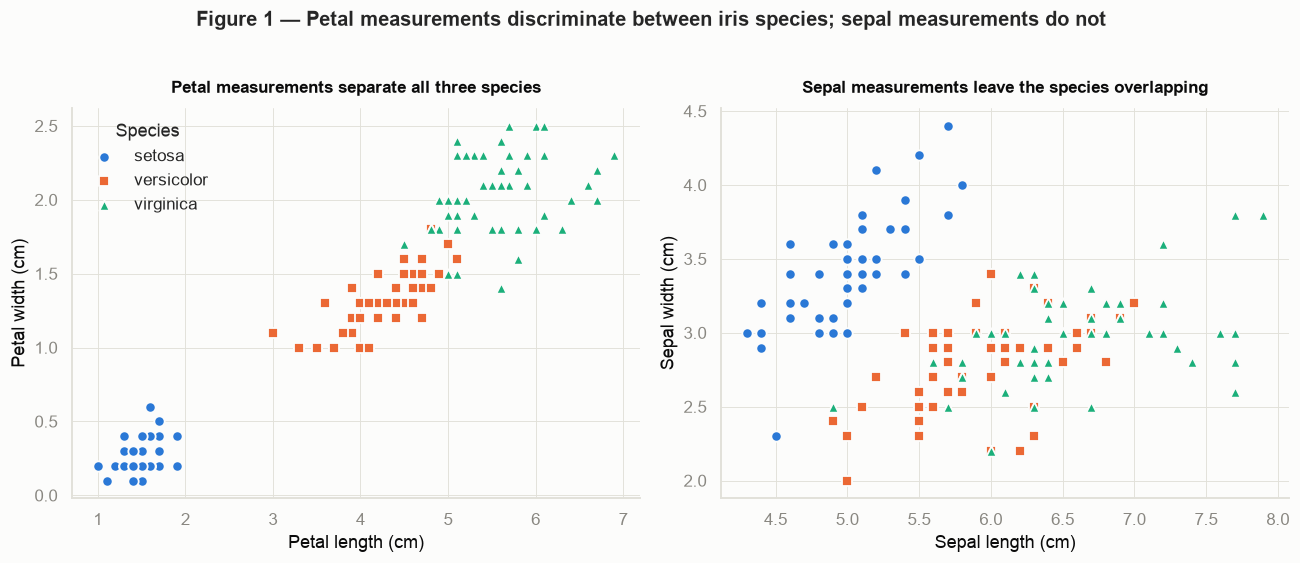

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

panels = [
    ("petal_length_cm", "petal_width_cm", "Petal length (cm)", "Petal width (cm)",
     "Petal measurements separate all three species"),
    ("sepal_length_cm", "sepal_width_cm", "Sepal length (cm)", "Sepal width (cm)",
     "Sepal measurements leave the species overlapping"),
]

for ax, (xcol, ycol, xlabel, ylabel, subtitle) in zip(axes, panels):
    for species in SPECIES_ORDER:
        subset = df[df["species"] == species]
        ax.scatter(
            subset[xcol], subset[ycol],
            s=46,
            color=SPECIES_COLORS[species],
            marker=SPECIES_MARKERS[species],
            linewidth=1.2,
            edgecolor=SURFACE,
            label=species,
        )
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(subtitle, fontsize=11, pad=10)
    ax.grid(True, linewidth=0.6, color=GRID)
    sns.despine(ax=ax)

axes[0].legend(title="Species", frameon=False, loc="upper left")

fig.suptitle(
    "Figure 1 — Petal measurements discriminate between iris species; "
    "sepal measurements do not",
    fontsize=13, fontweight="bold", y=1.02,
)
fig.tight_layout()
plt.show()

### Figure 2 - Distribution of each measurement by species

Small multiples rather than one crowded panel: the four measurements have
different ranges, so forcing them onto a shared axis would compress the petal
widths into a sliver. Each panel keeps its own y-axis and states its units.

Boxplots are used because the question concerns spread and overlap, not just
central tendency. The individual flowers are drawn behind each box at low opacity
so that the sample size and the shape of each distribution stay visible, which a
box alone hides.

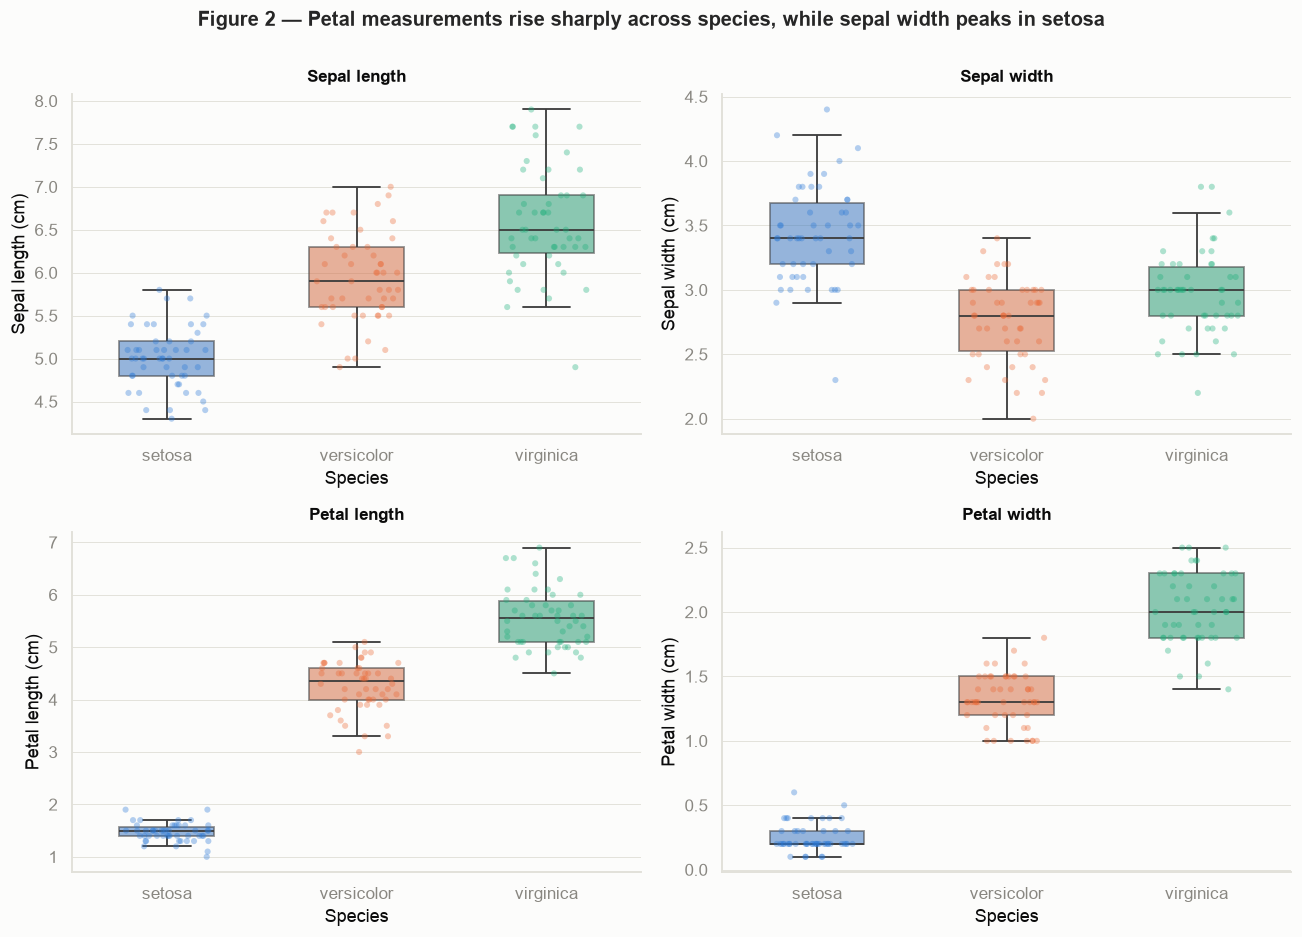

In [53]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))

titles = {
    "sepal_length_cm": "Sepal length",
    "sepal_width_cm":  "Sepal width",
    "petal_length_cm": "Petal length",
    "petal_width_cm":  "Petal width",
}

for ax, column in zip(axes.flat, MEASUREMENTS):
    sns.stripplot(
        data=df, x="species", y=column, order=SPECIES_ORDER,
        hue="species", hue_order=SPECIES_ORDER, palette=SPECIES_COLORS,
        legend=False, dodge=False, alpha=0.35, size=4, jitter=0.22, ax=ax,
    )
    sns.boxplot(
        data=df, x="species", y=column, order=SPECIES_ORDER,
        hue="species", hue_order=SPECIES_ORDER, palette=SPECIES_COLORS,
        legend=False, dodge=False, width=0.5, linewidth=1.2, fliersize=0,
        boxprops={"alpha": 0.55}, ax=ax,
    )
    ax.set_title(titles[column], fontsize=11, pad=8)
    ax.set_xlabel("Species")
    ax.set_ylabel(f"{titles[column]} (cm)")
    ax.grid(True, axis="y", linewidth=0.6, color=GRID)
    ax.grid(False, axis="x")
    sns.despine(ax=ax)

fig.suptitle(
    "Figure 2 — Petal measurements rise sharply across species, "
    "while sepal width peaks in setosa",
    fontsize=13, fontweight="bold", y=1.0,
)
fig.tight_layout()
plt.show()

### Figure 3 - Correlation between measurements

A diverging colour scale, because correlation has a natural zero and a sign: one
hue for positive, another for negative, and a neutral grey at exactly zero. The
scale is fixed to the full -1 to +1 range so that the neutral midpoint lands on
zero rather than on the middle of whatever happens to be in this dataset, which
would misrepresent weak correlations as neutral.

Only the lower triangle is drawn; a correlation matrix is symmetric, so the upper
half repeats information, and the now-empty first row and last column are dropped
rather than left as blank space. Every cell is labelled with its value, so the
figure does not rely on colour alone to be read; label colour flips to white on
the darkest cells to keep the numbers legible.

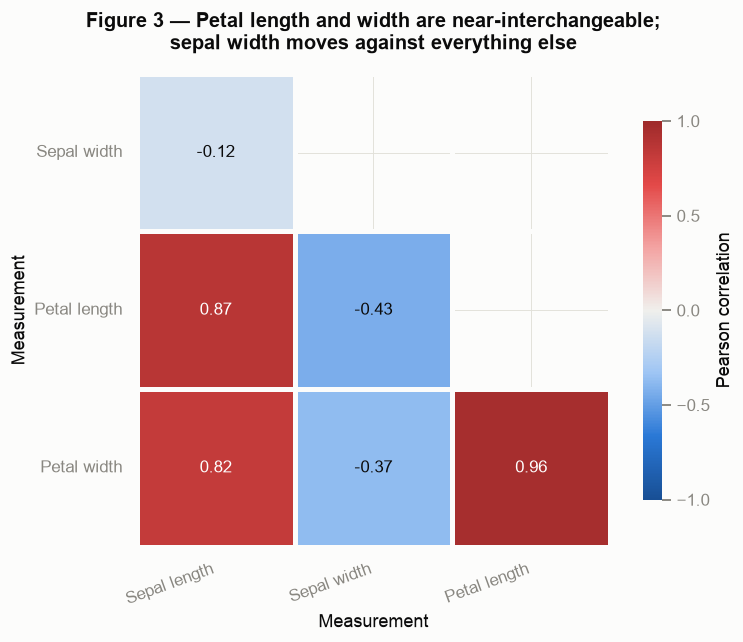

In [54]:
diverging = sns.blend_palette(
    ["#184f95", "#2a78d6", "#9ec5f4", "#f0efec", "#f3a3a2", "#e34948", "#9e2a2a"],
    as_cmap=True,
)

# Drop the row and column that the triangular mask would leave entirely empty.
lower = corr.iloc[1:, :-1]
mask = np.triu(np.ones_like(lower, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7.5, 6))

sns.heatmap(
    lower, mask=mask, cmap=diverging,
    vmin=-1, vmax=1, center=0,
    annot=True, fmt=".2f", annot_kws={"fontsize": 11},
    linewidths=2, linecolor=SURFACE, square=True,
    cbar_kws={"label": "Pearson correlation", "shrink": 0.8, "ticks": [-1, -0.5, 0, 0.5, 1]},
    xticklabels=[titles[c] for c in lower.columns],
    yticklabels=[titles[r] for r in lower.index],
    ax=ax,
)

# Dark cells need light text; pale cells need dark text.
for label in ax.texts:
    label.set_color("#ffffff" if abs(float(label.get_text())) > 0.6 else INK)

ax.set_title(
    "Figure 3 — Petal length and width are near-interchangeable;\n"
    "sepal width moves against everything else",
    fontsize=13, fontweight="bold", pad=16,
)
ax.set_xlabel("Measurement")
ax.set_ylabel("Measurement")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
plt.show()

### Figure 4 - Is the separation a gap or a shift?

Figures 1 and 2 show the species differ on petal length. This figure asks a
sharper question: is there a *range of values no flower occupies*, or do the
distributions merely sit at different averages while still overlapping? The
distinction decides whether a single measurement could classify a flower on its
own.

Histograms are drawn on a shared axis here, since the comparison is the point.
The shaded band marks the region no flower occupies. Bin edges are deliberately
offset to fall halfway between recordable values (measurements come at 0.1 cm
precision), so that no bar straddles the edge of the gap and visually fills a
region that is actually empty.

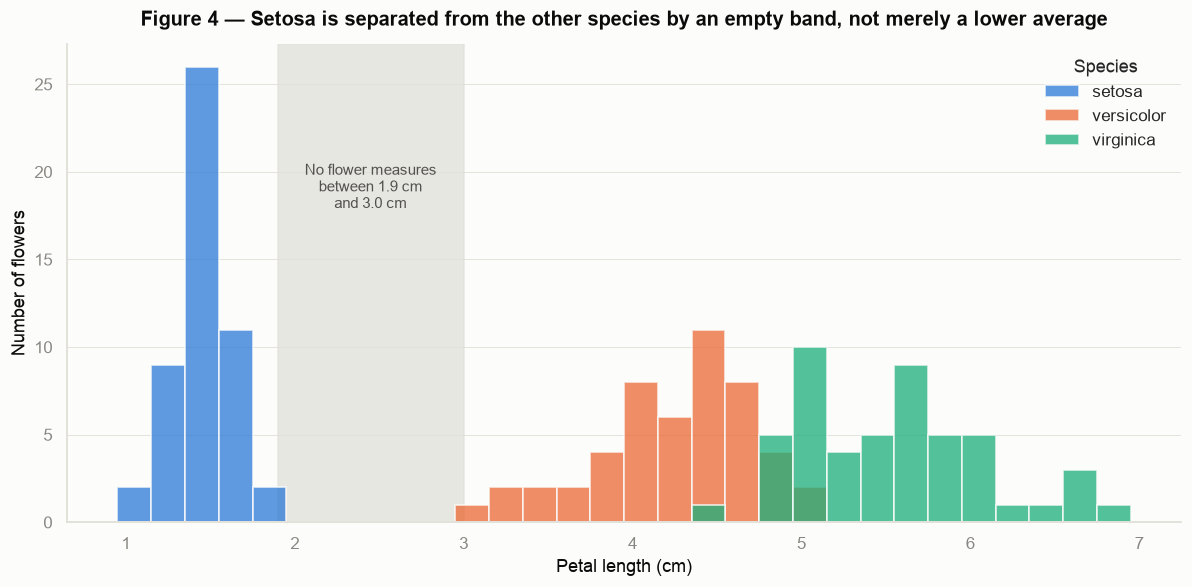

Largest setosa petal:              1.9 cm
Smallest non-setosa petal:         3.0 cm
Width of the unoccupied band:      1.1 cm


In [55]:
fig, ax = plt.subplots(figsize=(11, 5.5))

# Edges at x.x5 so that no bar can span the boundary of the empty band.
bins = np.arange(0.95, 7.15, 0.2)

for species in SPECIES_ORDER:
    ax.hist(
        df.loc[df["species"] == species, "petal_length_cm"],
        bins=bins, alpha=0.75,
        color=SPECIES_COLORS[species],
        edgecolor=SURFACE, linewidth=1.2,
        label=species,
    )

setosa_max = df.loc[df["species"] == "setosa", "petal_length_cm"].max()
others_min = df.loc[df["species"] != "setosa", "petal_length_cm"].min()

ax.axvspan(setosa_max, others_min, color=GRID, alpha=0.75, zorder=0)

ax.annotate(
    f"No flower measures\nbetween {setosa_max} cm\nand {others_min} cm",
    xy=((setosa_max + others_min) / 2, ax.get_ylim()[1] * 0.70),
    ha="center", va="center", fontsize=10, color="#52514e",
)

ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Number of flowers")
ax.set_title(
    "Figure 4 — Setosa is separated from the other species by an empty band, "
    "not merely a lower average",
    fontsize=13, fontweight="bold", pad=12,
)
ax.legend(title="Species", frameon=False)
ax.grid(True, axis="y", linewidth=0.6, color=GRID)
ax.grid(False, axis="x")
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

print(f"Largest setosa petal:              {setosa_max} cm")
print(f"Smallest non-setosa petal:         {others_min} cm")
print(f"Width of the unoccupied band:      {round(others_min - setosa_max, 2)} cm")

## 6. Summary and interpretation

### What I learned from the dataset

The four measurements do not contribute equally to telling the three species
apart, and the difference between them is large. Petal measurements carry almost
all of the discriminating information, while sepal measurements carry
comparatively little. The standardised separation table in Section 4 puts numbers
on this: setosa differs from virginica by about ten pooled standard deviations in
petal length, but by only about three in sepal length. A difference of ten pooled
standard deviations is not a tendency, it is a clean split.

The practical consequence is visible in Figure 4. Setosa's petals never exceed
1.9 cm in length, and no versicolor or virginica flower measures below 3.0 cm.
The 1.1 cm band between those values is completely unoccupied, so a single
measurement would classify every setosa in this sample correctly. That is a
stronger claim than "setosa has shorter petals on average," and it is the kind of
claim a plot of averages alone would have hidden.

### Interesting patterns

Three patterns stood out.

First, the three species are not symmetrically arranged. Setosa is cleanly
separated from both others, while versicolor and virginica overlap each other in
every single measurement. The common summary that "Iris has three distinct
species" is only two-thirds true: the dataset really contains one easy problem
and one hard one, and Figure 1 shows the hard pair sharing a boundary region
where no straight line separates them.

Second, sepal width runs in the opposite direction to everything else. It is the
only measurement that is negatively correlated with the others (Figure 3), and
the only one on which setosa scores *highest* rather than lowest. Setosa is
therefore not simply a smaller flower: it has short, narrow petals on relatively
wide sepals, a genuinely different shape rather than a scaled-down version of the
same shape.

Third, petal length and petal width are correlated at 0.96, which is high enough
that they are nearly interchangeable as evidence. Figure 1's left panel looks
informative, but much of its apparent two-dimensionality is redundant; the points
fall close to a line. Four measurements are recorded, but they do not supply four
independent pieces of information.

### Limitations and assumptions

The most important limitation is that this is a small, balanced, and curated
sample: exactly 50 flowers per species, collected in the mid-1930s from a setting
and, for two of the three species, from the same pasture on the same day. The
clean separation found here should not be read as a general fact about irises in
the wild. Nothing in this notebook supports extrapolation to other populations,
and the perfectly equal class sizes are a property of the study design rather
than of nature.

Two analytical assumptions are worth stating. Pearson correlation measures linear
association, so Figure 3 would understate a relationship that is strong but
curved. The standardised separation measure pools standard deviations across two
groups, which is most meaningful when those groups have comparable spread; the
grouped table shows setosa's petal measurements are considerably less variable
than the others, so its separation values should be treated as indicative rather
than exact.

Finally, measurements are recorded to 0.1 cm. That precision is coarse relative
to the differences between versicolor and virginica, and it is the direct cause
of the duplicate row discussed in Section 3. Two distinguishable flowers can
easily round to the same four values.

### What was surprising or remains unclear

The genuine surprise was that a dataset with a reputation for being pristine
contained two documented transcription errors. They are described in the
`iris.names` file distributed alongside the data, and they are easy to miss
precisely because they do not look like errors: the two corrupted rows read as a
plausible duplicate pair. Had I run a routine "drop duplicates" step without
reading the documentation first, I would have deleted a real flower and never
known. The lesson generalises beyond this dataset: the documentation shipped with
data is part of the data, and automated cleaning rules applied without reading it
can destroy information while appearing to improve quality.

One thing remains genuinely unclear. The remaining duplicate at sample 143 cannot
be resolved from the data alone. It may be two distinct flowers that round to
identical values, or it may be a single flower recorded twice during
transcription. I kept it, because deleting a real observation is the more harmful
error of the two and because removing it would unbalance the class sizes. But I
cannot demonstrate that this was correct, and I have flagged it rather than
resolved it.

### Where this would go next

The obvious next question is whether versicolor and virginica can be separated
using combinations of measurements rather than any single one. Figure 1 suggests a
diagonal boundary in petal space would do considerably better than either axis
alone, which is a question for a classification model and outside the scope of
this workflow module.